<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/03.%20Dimensionality%20Reduction/Chapter_03_Dimensionality_Reduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 3: Dimensionality Reduction Techniques

Imagine making soup from a cookbook. Not satisfied with the recipe, you add a few extra ingredients and remove others. The result is a ruined soup. The right combination of *ingredients* matters in cooking and also in ML: the **features** we train on strongly influence model performance. This chapter is about finding the right ingredients by **reducing the number of features** while keeping as much useful information as possible.

**What this notebook covers**

1. Why dimensionality reduction is needed, including the *curse of dimensionality* (with two small experiments)
2. Feature selection versus feature extraction
3. **PCA** (Principal Component Analysis): intuition, the maths from scratch, explained variance, reconstruction, and the importance of scaling
4. **LDA** (Linear Discriminant Analysis): maximising class separability, and how it differs from PCA
5. **t-SNE** (t-distributed Stochastic Neighbor Embedding): non-linear embedding for visualisation, hyperparameters, and caveats
6. How to **choose** between the techniques
7. The **impact on model performance**: trade-offs, plus the two practical examples from the book (PCA + logistic regression on Iris, t-SNE + K-means on digits)

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 3. Datasets used: **Wine**, **Digits** (a small MNIST-like set of 8×8 handwritten digits), **Iris**, all bundled with scikit-learn.

In [1]:
import time
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.datasets import load_wine, load_digits, load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.manifold import TSNE
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

np.random.seed(2024)                        # reproducibility, as in the book
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)
sns.set_theme(style="whitegrid")

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version:        2.4.4
pandas version:       3.0.2


## 1. Introduction to Dimensionality Reduction

**Dimensionality reduction** reduces the number of features (dimensions) in a dataset while retaining as much relevant information as possible. It is as fundamental as the preprocessing from Chapter 2. Beginners are often tempted to throw every available feature into a model, but more data is only better when it relates to the problem. Irrelevant features add noise ("garbage in, garbage out").

### 1.1 Why it is essential

| Goal | Explanation |
|:-----|:------------|
| **Simplify data** | Fewer features are easier to interpret and analyse |
| **Reduce computational cost** | Faster training, less memory, feasible on bigger data |
| **Improve generalisation** | Removing noisy/redundant features reduces *overfitting* |
| **Enable visualisation** | We can only plot 2 or 3 dimensions; we cannot imagine a fifth |

### 1.2 The curse of dimensionality: two experiments

As the number of dimensions grows, the space becomes exponentially larger and data become **sparse**. Two classical consequences:

**Experiment 1: distances lose their meaning.** For random points in a $d$-dimensional cube, the distance to the *nearest* point and to the *farthest* point become almost equal as $d$ grows. We measure the relative contrast $\dfrac{d_{\max}-d_{\min}}{d_{\min}}$ from a random query point to 1000 random points.

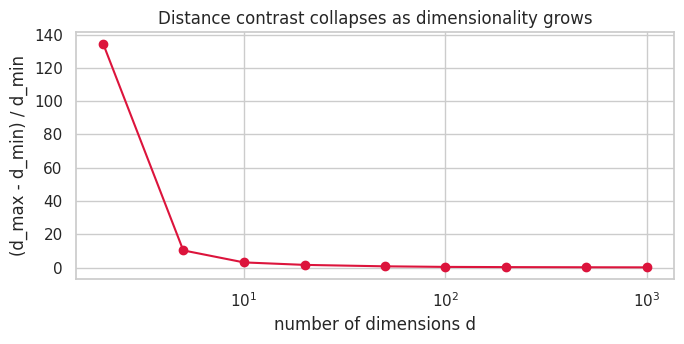

   d  relative contrast
   2           134.6179
   5            10.3169
  10             3.0888
  20             1.6020
  50             0.7399
 100             0.3921
 200             0.2647
 500             0.1690
1000             0.1153


In [2]:
rng = np.random.default_rng(0)
dims = [2, 5, 10, 20, 50, 100, 200, 500, 1000]
contrast = []
for d in dims:
    X = rng.uniform(size=(1000, d))
    q = rng.uniform(size=(1, d))
    dist = np.linalg.norm(X - q, axis=1)
    contrast.append((dist.max() - dist.min()) / dist.min())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogx(dims, contrast, "o-", color="crimson")
ax.set_xlabel("number of dimensions d"); ax.set_ylabel("(d_max - d_min) / d_min")
ax.set_title("Distance contrast collapses as dimensionality grows")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"d": dims, "relative contrast": contrast}).to_string(index=False))

In 2 dimensions the farthest point is many times farther than the nearest one; at 1000 dimensions all points are at *nearly the same distance*. Algorithms that rely on distances (KNN, K-means, RBF-SVM) lose their discriminating power in such spaces.

**Experiment 2: useless features hurt a KNN classifier.** We take the Wine dataset (13 informative features), standardise it, and append an increasing number of pure-noise features.

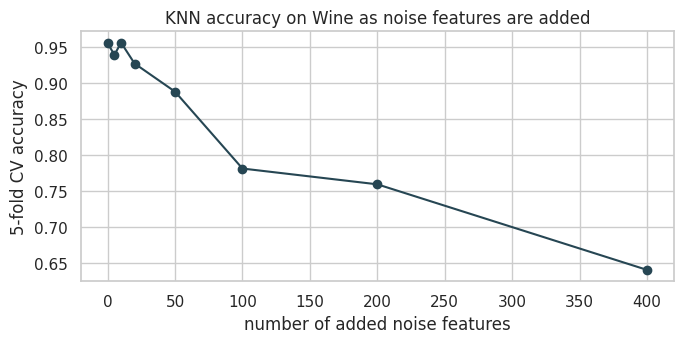

 noise features  CV accuracy
              0       0.9551
              5       0.9384
             10       0.9554
             20       0.9265
             50       0.8875
            100       0.7808
            200       0.7589
            400       0.6402


In [3]:
wine = load_wine(as_frame=True)
Xw, yw = wine.data, wine.target
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2024)

rng = np.random.default_rng(1)
n_noise_list = [0, 5, 10, 20, 50, 100, 200, 400]
accs = []
for k in n_noise_list:
    X_aug = np.hstack([Xw.values, rng.normal(size=(len(Xw), k))]) if k else Xw.values
    pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
    accs.append(cross_val_score(pipe, X_aug, yw, cv=cv).mean())

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(n_noise_list, accs, "o-", color="#264653")
ax.set_xlabel("number of added noise features"); ax.set_ylabel("5-fold CV accuracy")
ax.set_title("KNN accuracy on Wine as noise features are added")
plt.tight_layout(); plt.show()
print(pd.DataFrame({"noise features": n_noise_list, "CV accuracy": accs}).to_string(index=False))

Accuracy falls overall as irrelevant dimensions are added (with small fluctuations when only a few are added), from about 95% to about 64% with 400 noise features, even though the 13 informative features are still there. Dimensionality reduction is the remedy: keep the directions that carry signal and discard the rest.

### 1.3 Two families of techniques

**Feature selection** keeps a *subset* of the original features unchanged. It was introduced in Chapter 2:
- *Filter* methods score features by statistics (correlation, F-test).
- *Wrapper* methods evaluate feature subsets by training models (RFE).
- *Embedded* methods select during training (Lasso).

**Feature extraction** builds *new* features as combinations of the originals, in a lower-dimensional space:

| Technique | Supervised? | Idea |
|:----------|:-----------:|:-----|
| **PCA** | No | Find orthogonal directions of maximum variance |
| **LDA** | Yes | Find directions that best separate the classes |
| **t-SNE** | No | Embed points in 2-3 D preserving local neighbourhoods (visualisation) |

**General recipe**
1. Assess the dimensionality of the dataset and the problems it may cause.
2. Decide whether you need selection or extraction, depending on your goal.
3. Apply the method with scikit-learn.
4. Train models on the original and reduced data and compare.

## 2. Transforming Datasets with PCA

**Principal Component Analysis** is the most widely used linear dimensionality reduction technique. It re-expresses the data in a new coordinate system whose axes, the **principal components** (PCs), are:

- **orthogonal** (perpendicular) to one another,
- ordered by the amount of **variance** of the data they capture: PC1 captures the most, PC2 the most of what remains, and so on.

Keeping only the first few components gives a compact representation that preserves most of the variability.

### 2.1 Getting ready: the Wine dataset

The Wine dataset contains 178 samples of Italian wines from 3 cultivars, described by 13 chemical measurements. Two rules before PCA:
1. **Standardise** the features (PCA is variance-based, so large-scale features would dominate).
2. **Separate the target** from the features; the target must not be part of the PCA.

In [4]:
df_wine = wine.data
target_wine = wine.target
print("Shape:", df_wine.shape, "| classes:", list(wine.target_names), "| samples per class:", np.bincount(target_wine))
df_wine.head(6)

Shape: (178, 13) | classes: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')] | samples per class: [59 71 48]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.2300,1.7100,2.4300,15.6000,127.0000,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065.0000
1,13.2000,1.7800,2.1400,11.2000,100.0000,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050.0000
2,13.1600,2.3600,2.6700,18.6000,101.0000,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185.0000
3,14.3700,1.9500,2.5000,16.8000,113.0000,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480.0000
4,13.2400,2.5900,2.8700,21.0000,118.0000,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735.0000
5,14.2000,1.7600,2.4500,15.2000,112.0000,3.2700,3.3900,0.3400,1.9700,6.7500,1.0500,2.8500,1450.0000


### 2.2 PCA in a pipeline

As in the book, we chain the scaler and PCA with a `Pipeline` (the convention for the rest of the repository). We reduce the 13 features to 2 components.

In [5]:
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),          # always scale before PCA
    ("pca", PCA(n_components=2)),          # reduce to 2 dimensions
])
X_pca = pca_pipeline.fit_transform(df_wine)
pca = pca_pipeline.named_steps["pca"]

print("Output shape:", X_pca.shape)
print("Explained variance ratio of PC1, PC2:", np.round(pca.explained_variance_ratio_, 4))
print(f"Total variance explained by 2 components: {pca.explained_variance_ratio_.sum():.2%}")

Output shape: (178, 2)
Explained variance ratio of PC1, PC2: [0.362  0.1921]
Total variance explained by 2 components: 55.41%


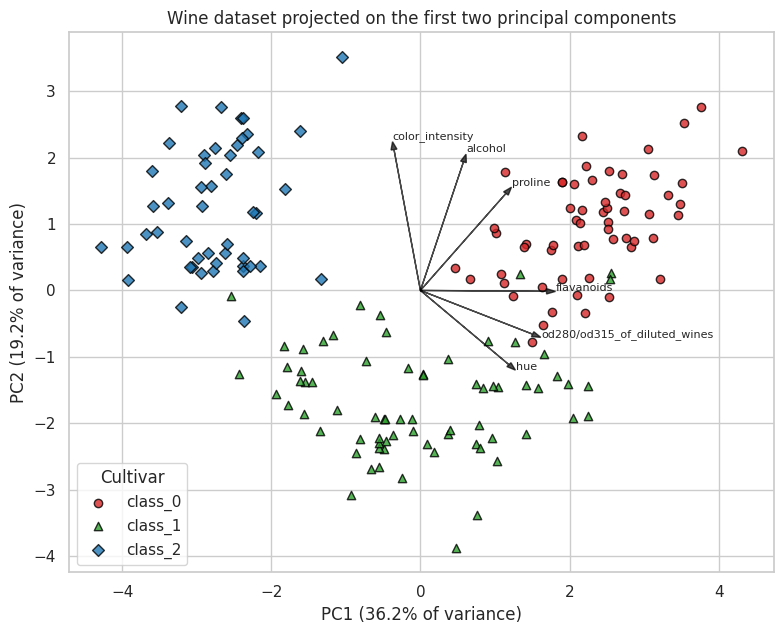

In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
shapes, colors = ["o", "^", "D"], ["tab:red", "tab:green", "tab:blue"]
for i, (shape, color) in enumerate(zip(shapes, colors)):
    ax.scatter(X_pca[target_wine == i, 0], X_pca[target_wine == i, 1], c=color, marker=shape,
               edgecolor="black", alpha=0.8, label=wine.target_names[i])

# Loading arrows: how strongly each ORIGINAL feature contributes to PC1 and PC2 (top 6 by length)
loadings = pca.components_.T                                   # shape (13, 2)
top = np.argsort(np.linalg.norm(loadings, axis=1))[-6:]
for j in top:
    ax.arrow(0, 0, loadings[j, 0] * 4, loadings[j, 1] * 4, color="black", head_width=0.08, alpha=0.7)
    ax.text(loadings[j, 0] * 4.3, loadings[j, 1] * 4.3, df_wine.columns[j], fontsize=8)

ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
ax.set_title("Wine dataset projected on the first two principal components")
ax.legend(title="Cultivar"); plt.tight_layout(); plt.show()

Even without using the class labels, the three cultivars form three fairly distinct groups in the PC1-PC2 plane. The arrows (a *biplot*) show which original features drive each axis: features pointing in the same direction as an arrow are positively correlated with that component.

> **Reading note.** The book draws arrows for the first two *components*; here the arrows are the *loadings of the original features* on PC1/PC2, which is the standard biplot and easier to interpret.

### 2.3 How PCA works: building it from scratch

The algorithm in five steps:

1. **Standardise** the data (mean 0, variance 1).
2. Compute the **covariance matrix** $\Sigma = \dfrac{1}{n-1}X^\top X$ (for standardised $X$ this is the correlation matrix).
3. Find its **eigenvalues** $\lambda_i$ and **eigenvectors** $\mathbf{v}_i$: $\;\Sigma\,\mathbf{v}_i=\lambda_i\,\mathbf{v}_i$. Eigenvectors are the principal directions; eigenvalues are the variance captured along each.
4. **Select** the top $k$ eigenvectors (largest eigenvalues) to form a projection matrix $W_k$.
5. **Project**: $Z = X\,W_k$.

The fraction of variance explained by component $i$ is

$$\text{EVR}_i = \frac{\lambda_i}{\sum_{j=1}^{p}\lambda_j}.$$

Let's implement this with NumPy and check that it agrees with scikit-learn.

In [7]:
Xs = StandardScaler().fit_transform(df_wine)             # step 1
cov = np.cov(Xs, rowvar=False)                           # step 2 (uses n-1)
eigvals, eigvecs = np.linalg.eigh(cov)                   # step 3 (eigh: for symmetric matrices)
order = np.argsort(eigvals)[::-1]                        # sort by decreasing eigenvalue
eigvals, eigvecs = eigvals[order], eigvecs[:, order]

W2 = eigvecs[:, :2]                                      # step 4
Z_manual = Xs @ W2                                       # step 5

pca_full = PCA().fit(Xs)
print("Top-5 eigenvalues (manual)   :", np.round(eigvals[:5], 4))
print("explained_variance_ (sklearn):", np.round(pca_full.explained_variance_[:5], 4))

# Eigenvectors are only defined up to a sign, so compare absolute cosine similarity
cos = [abs(np.dot(eigvecs[:, i], pca_full.components_[i])) for i in range(3)]
print("\n|cosine| between manual and sklearn components 1-3:", np.round(cos, 6))
print("Projected data identical up to sign:", np.allclose(np.abs(Z_manual), np.abs(X_pca)))
print("EVR (manual) of first 2 PCs:", np.round(eigvals[:2] / eigvals.sum(), 4))

Top-5 eigenvalues (manual)   : [4.7324 2.5111 1.4542 0.9242 0.858 ]
explained_variance_ (sklearn): [4.7324 2.5111 1.4542 0.9242 0.858 ]

|cosine| between manual and sklearn components 1-3: [1. 1. 1.]
Projected data identical up to sign: True
EVR (manual) of first 2 PCs: [0.362  0.1921]


Our 10-line NumPy implementation reproduces scikit-learn exactly (eigenvectors may differ by a sign, which is mathematically irrelevant). Internally scikit-learn uses the numerically more stable **singular value decomposition (SVD)** of the centred data matrix, but the result is equivalent.

### 2.4 Choosing the number of components: the scree plot

How many components should we keep? Plot the explained variance of every component and its cumulative sum (a *scree plot*), then keep enough components to reach a target such as 90-95% of the total variance.

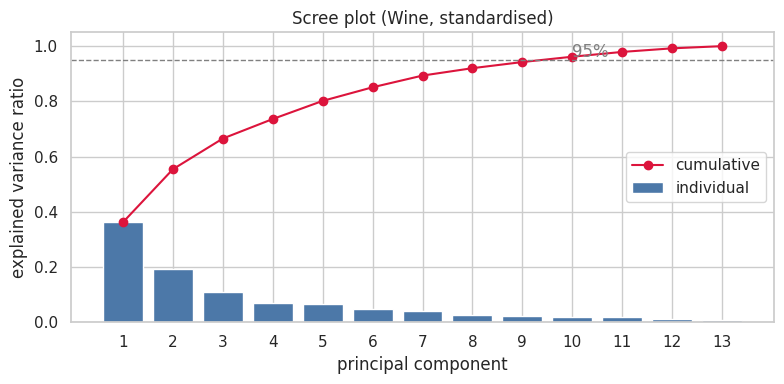

Cumulative variance: [0.362 0.554 0.665 0.736 0.802 0.851 0.893 0.92 ] ...
  components needed for 80% of the variance: 5
  components needed for 90% of the variance: 8
  components needed for 95% of the variance: 10
  components needed for 99% of the variance: 12


In [8]:
evr = pca_full.explained_variance_ratio_
cum = np.cumsum(evr)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(1, 14), evr, color="#4c78a8", label="individual")
ax.plot(range(1, 14), cum, "o-", color="crimson", label="cumulative")
ax.axhline(0.95, color="gray", ls="--", lw=1); ax.text(10, 0.96, "95%", color="gray")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance ratio"); ax.set_xticks(range(1, 14))
ax.set_title("Scree plot (Wine, standardised)"); ax.legend(loc="center right")
plt.tight_layout(); plt.show()

print("Cumulative variance:", np.round(cum[:8], 3), "...")
for target in [0.80, 0.90, 0.95, 0.99]:
    print(f"  components needed for {target:.0%} of the variance: {int(np.searchsorted(cum, target) + 1)}")

The first two components explain a bit more than half of the total variance (the book reports 55.41%), which is enough to visually separate the classes, but a faithful representation of the data requires more: about 8 components for 90%. The right number depends on the goal: **2** for plotting, **enough for 90-95%** for modelling.

scikit-learn can choose automatically: giving a float between 0 and 1 as `n_components` keeps just enough components to reach that fraction of variance.

In [9]:
pca_95 = make_pipeline(StandardScaler(), PCA(n_components=0.95)).fit(df_wine)
print("PCA(n_components=0.95) kept", pca_95[-1].n_components_, "components "
      f"explaining {pca_95[-1].explained_variance_ratio_.sum():.2%} of the variance")

PCA(n_components=0.95) kept 10 components explaining 96.17% of the variance


### 2.5 Interpreting the components: loadings

Each principal component is a **linear combination** of the original features. The coefficients (`pca.components_`) are called **loadings**. A large absolute loading means the feature contributes strongly to that component.

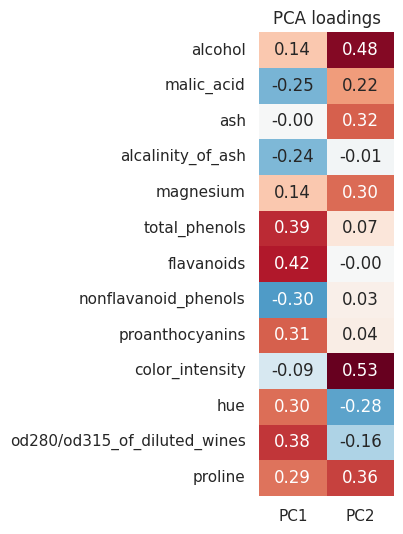

Features with the largest |loading| on PC1: ['flavanoids', 'total_phenols', 'od280/od315_of_diluted_wines']
Features with the largest |loading| on PC2: ['color_intensity', 'alcohol', 'proline']


In [10]:
loadings_df = pd.DataFrame(pca.components_.T, index=df_wine.columns, columns=["PC1", "PC2"])
fig, ax = plt.subplots(figsize=(4.2, 5.5))
sns.heatmap(loadings_df, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False, ax=ax)
ax.set_title("PCA loadings"); plt.tight_layout(); plt.show()
print("Features with the largest |loading| on PC1:", list(loadings_df["PC1"].abs().sort_values(ascending=False).index[:3]))
print("Features with the largest |loading| on PC2:", list(loadings_df["PC2"].abs().sort_values(ascending=False).index[:3]))

PC1 is dominated by features such as `flavanoids`, `total_phenols` and `od280/od315...` (phenolic content), while PC2 is driven mostly by `color_intensity`, `alcohol` and `proline`. PCs are therefore *abstract* axes: useful, but harder to explain than original features, which is the interpretability cost of feature extraction.

### 2.6 Why scaling before PCA is mandatory

PCA maximises variance. If one feature has a much larger numeric range, it has a much larger variance and will dominate PC1, regardless of its importance. We compare PCA with and without standardisation on Wine (where `proline` takes values in the hundreds/thousands).

In [11]:
pca_raw = PCA(n_components=2).fit(df_wine)                 # NO scaling
pca_std = PCA(n_components=2).fit(StandardScaler().fit_transform(df_wine))

print("Without scaling: explained variance ratio =", np.round(pca_raw.explained_variance_ratio_, 4))
top_raw = df_wine.columns[np.argmax(np.abs(pca_raw.components_[0]))]
print(f"  -> PC1 is essentially the single feature '{top_raw}' (|loading| = {np.abs(pca_raw.components_[0]).max():.3f})")
print("\nWith scaling   : explained variance ratio =", np.round(pca_std.explained_variance_ratio_, 4))
print(f"  -> PC1 loading is spread out; largest |loading| = {np.abs(pca_std.components_[0]).max():.3f}")

Without scaling: explained variance ratio = [0.9981 0.0017]
  -> PC1 is essentially the single feature 'proline' (|loading| = 1.000)

With scaling   : explained variance ratio = [0.362  0.1921]
  -> PC1 loading is spread out; largest |loading| = 0.423


Without scaling, PC1 "explains" almost all the variance, but only because it is simply the `proline` column (the feature with the largest numbers); the other twelve measurements are effectively ignored. After standardisation the variance is distributed realistically across components. **Always standardise before PCA** unless all features share the same units and scale.

### 2.7 Reconstruction: how much information is lost?

Because PCA is linear, we can map the reduced data back to the original space with `inverse_transform()`. The **reconstruction error** quantifies the information thrown away:

$$\text{MSE}_{\text{recon}} = \frac{1}{n p}\sum_{i,j}\left(x_{ij}-\hat{x}_{ij}\right)^2$$

It decreases to zero when all components are kept. We show it for Wine and then visually for the Digits images, which make "information loss" tangible.

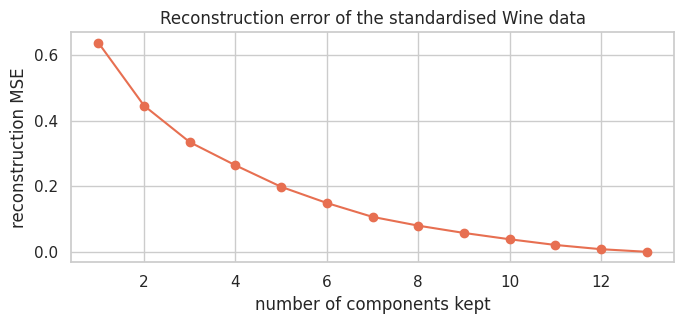

Error with 2 components : 0.4459
Error with 13 components: 0.0 (lossless)


In [12]:
ks = list(range(1, 14))
errors = []
for k in ks:
    p = PCA(n_components=k).fit(Xs)
    errors.append(np.mean((Xs - p.inverse_transform(p.transform(Xs))) ** 2))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(ks, errors, "o-", color="#e76f51")
ax.set_xlabel("number of components kept"); ax.set_ylabel("reconstruction MSE")
ax.set_title("Reconstruction error of the standardised Wine data")
plt.tight_layout(); plt.show()

print("Error with 2 components :", round(errors[1], 4))
print("Error with 13 components:", round(errors[-1], 10), "(lossless)")

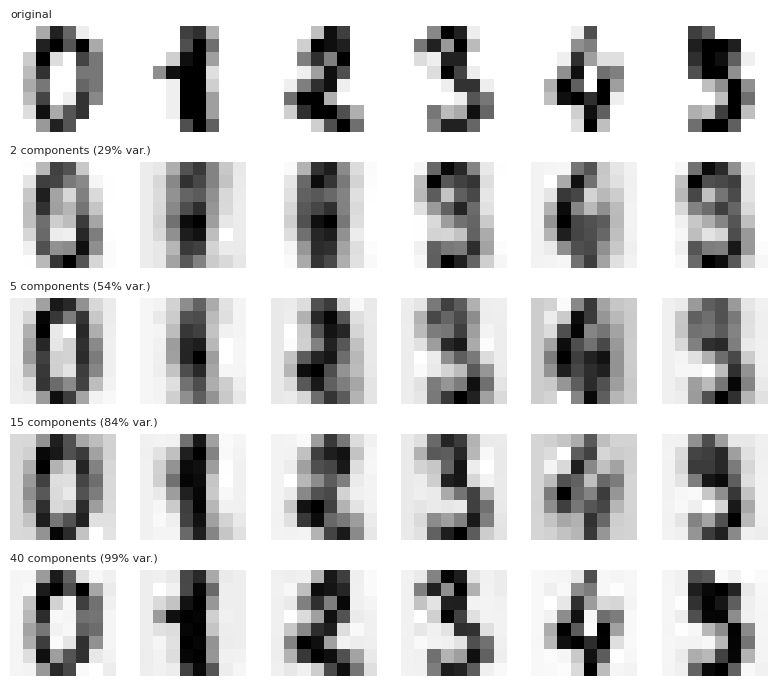

In [13]:
digits = load_digits()
Xd, yd = digits.data, digits.target
ks_show = [2, 5, 15, 40]

fig, axes = plt.subplots(len(ks_show) + 1, 6, figsize=(8, 7))
for col in range(6):
    axes[0, col].imshow(Xd[col].reshape(8, 8), cmap="gray_r"); axes[0, col].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left")
for row, k in enumerate(ks_show, start=1):
    p = PCA(n_components=k).fit(Xd)
    rec = p.inverse_transform(p.transform(Xd[:6]))
    for col in range(6):
        axes[row, col].imshow(rec[col].reshape(8, 8), cmap="gray_r"); axes[row, col].axis("off")
    axes[row, 0].set_title(f"{k} components ({p.explained_variance_ratio_.sum():.0%} var.)", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

With only 2 components the digits are blurry blobs; with 15 they are recognisable; with 40 of the 64 pixels' worth of information they are nearly perfect. This is *lossy compression*: PCA keeps the strongest patterns first.

### 2.8 Non-linear structure: a note on `KernelPCA`

PCA is **linear**: it can only rotate and project. If the structure is curved (for example concentric circles), no linear projection can separate it. `KernelPCA` applies the "kernel trick" to find non-linear principal components.

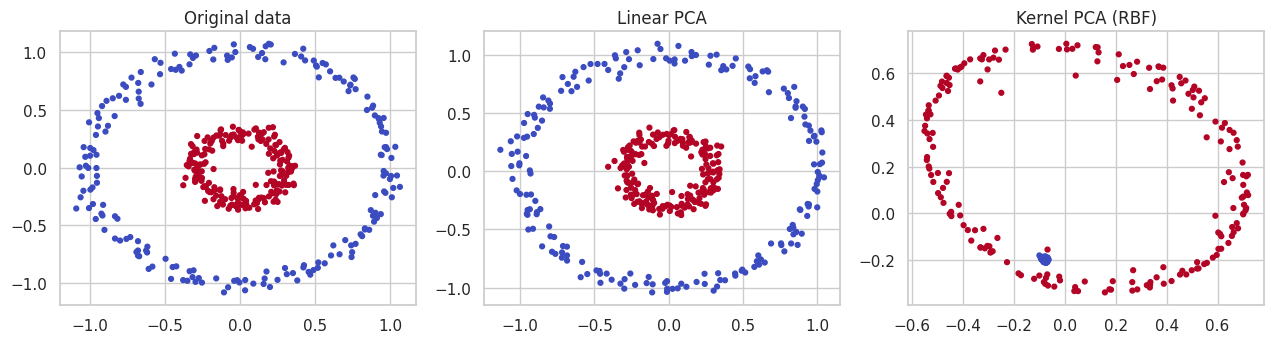

In [14]:
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA

Xc, yc = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=2024)
lin = PCA(n_components=2).fit_transform(Xc)
ker = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit_transform(Xc)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (title, Z) in zip(axes, [("Original data", Xc), ("Linear PCA", lin), ("Kernel PCA (RBF)", ker)]):
    ax.scatter(Z[:, 0], Z[:, 1], c=yc, cmap="coolwarm", s=12); ax.set_title(title)
plt.tight_layout(); plt.show()

Linear PCA merely rotates the circles; they remain nested and cannot be separated by a line along any single component. Kernel PCA "unfolds" them so that the two classes become separable along the first component. For large datasets, `IncrementalPCA` and the randomised SVD solver (`svd_solver="randomized"`) are the scalable variants of PCA.

### 2.9 Hands-on checklist for PCA
1. Understand the dimensionality of the data and the problems it may cause.
2. Make sure the features are on a similar scale (standardise).
3. Fit `PCA` and inspect the explained variance.
4. Visualise the transformed data and judge how well it works.
5. Use the reduced features in subsequent modelling.

## 3. Maximising Class Separability with LDA

**Linear Discriminant Analysis** is a **supervised** dimensionality reduction technique. While PCA ignores labels and looks only for variance, LDA looks for the directions that **best separate the classes**.

### 3.1 The idea (Fisher's criterion)

LDA seeks a projection vector $\mathbf{w}$ that maximises the ratio of **between-class** scatter to **within-class** scatter:

$$J(\mathbf{w})=\frac{\mathbf{w}^\top S_B\,\mathbf{w}}{\mathbf{w}^\top S_W\,\mathbf{w}}$$

with

$$S_W=\sum_{c}\sum_{\mathbf{x}\in c}(\mathbf{x}-\boldsymbol{\mu}_c)(\mathbf{x}-\boldsymbol{\mu}_c)^\top, \qquad S_B=\sum_{c}n_c(\boldsymbol{\mu}_c-\boldsymbol{\mu})(\boldsymbol{\mu}_c-\boldsymbol{\mu})^\top$$

where $\boldsymbol{\mu}_c$ is the mean of class $c$ and $\boldsymbol{\mu}$ the overall mean. In words: *push class means far apart, keep each class tight.* The solution is given by the leading eigenvectors of $S_W^{-1}S_B$.

**Assumptions:** each class is approximately Gaussian, and all classes share the same covariance matrix.

**Limit on components:** LDA can produce at most $\min(p,\; C-1)$ components, with $p$ features and $C$ classes. For Wine that is $\min(13, 3-1)=2$.

In [15]:
X_wine, y_wine = wine.data, wine.target

lda_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis(n_components=2)),     # min(n_features, n_classes - 1) = 2
])
X_lda = lda_pipeline.fit_transform(X_wine, y_wine)              # NOTE: LDA needs the labels y
lda = lda_pipeline.named_steps["lda"]

print("Output shape:", X_lda.shape)
print("Explained variance ratio of the two discriminants:", np.round(lda.explained_variance_ratio_, 4))

# The limit on the number of components
try:
    LinearDiscriminantAnalysis(n_components=3).fit(StandardScaler().fit_transform(X_wine), y_wine)
except ValueError as e:
    print("\nAsking for 3 components raises ValueError:", str(e)[:95], "...")

Output shape: (178, 2)
Explained variance ratio of the two discriminants: [0.6875 0.3125]

Asking for 3 components raises ValueError: n_components cannot be larger than min(n_features, n_classes - 1). ...


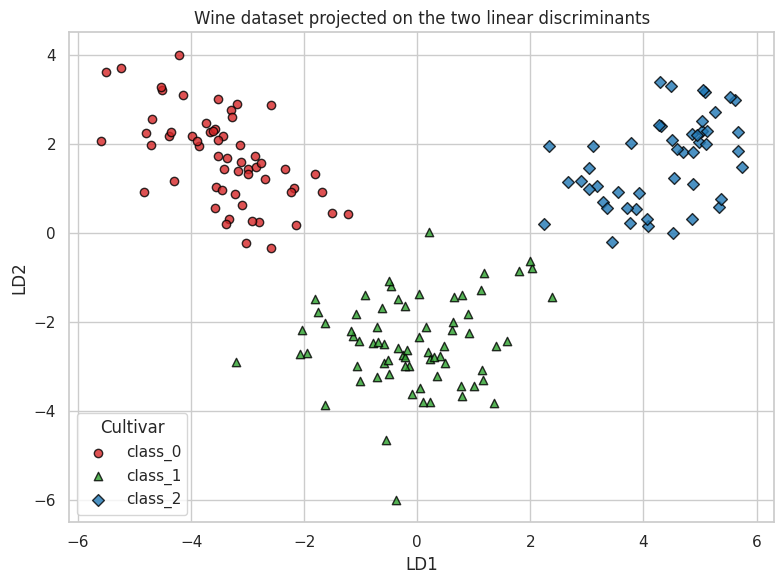

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))
for i, (shape, color) in enumerate(zip(shapes, colors)):
    ax.scatter(X_lda[y_wine == i, 0], X_lda[y_wine == i, 1], c=color, marker=shape, edgecolor="black",
               alpha=0.8, label=wine.target_names[i])
ax.set_xlabel("LD1"); ax.set_ylabel("LD2"); ax.set_title("Wine dataset projected on the two linear discriminants")
ax.legend(title="Cultivar"); plt.tight_layout(); plt.show()

The three classes form tight, well-separated clusters, even more clearly than with PCA, because LDA was explicitly told to separate them. (The first discriminant, LD1, carries most of the separation, as the explained-variance ratios show.)

### 3.2 PCA versus LDA

| Aspect | PCA | LDA |
|:-------|:----|:----|
| Supervised? | No (ignores labels) | Yes (needs labels) |
| Objective | Maximise total variance | Maximise class separability |
| Max components | $\min(n, p)$ | $\min(p, C-1)$ |
| Components | Orthogonal | Not necessarily orthogonal |
| Typical use | Exploration, compression, denoising | Pre-processing for classification |
| Assumptions | None (linear structure) | Gaussian classes, equal covariance |

Side by side on Wine:

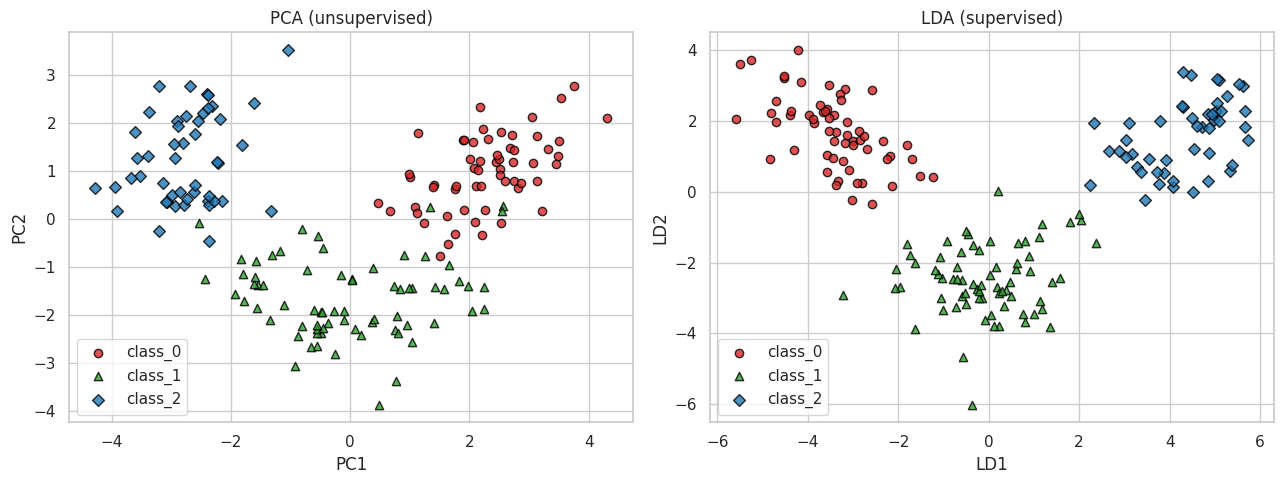

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, Z, xl, yl) in zip(axes, [("PCA (unsupervised)", X_pca, "PC1", "PC2"), ("LDA (supervised)", X_lda, "LD1", "LD2")]):
    for i, (shape, color) in enumerate(zip(shapes, colors)):
        ax.scatter(Z[y_wine == i, 0], Z[y_wine == i, 1], c=color, marker=shape, edgecolor="black", alpha=0.8, label=wine.target_names[i])
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylabel(yl); ax.legend()
plt.tight_layout(); plt.show()

Visually LDA separates the classes a little more sharply. But beware: part of this advantage is *by construction*, because LDA uses the labels. To judge fairly we must measure performance on **held-out** data. We project with each method (fitted on the training set only) and classify the test samples with KNN in the 2-D space.

In [18]:
from sklearn.metrics import silhouette_score

Xtr, Xte, ytr, yte = train_test_split(X_wine, y_wine, test_size=0.3, stratify=y_wine, random_state=0)

rows = []
for name, reducer in {"PCA (2 comp.)": PCA(n_components=2),
                      "LDA (2 comp.)": LinearDiscriminantAnalysis(n_components=2)}.items():
    pipe = make_pipeline(StandardScaler(), reducer).fit(Xtr, ytr)
    Ztr, Zte = pipe.transform(Xtr), pipe.transform(Xte)
    knn = KNeighborsClassifier(n_neighbors=5).fit(Ztr, ytr)
    rows.append({"method": name,
                 "silhouette (train, true labels)": silhouette_score(Ztr, ytr),
                 "KNN accuracy on held-out test": knn.score(Zte, yte)})

# Reference: LDA used directly as a classifier on the 13 original features
lda_clf = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()).fit(Xtr, ytr)
print(pd.DataFrame(rows).set_index("method"))
print(f"\nReference: LDA as a classifier on all 13 features, test accuracy = {lda_clf.score(Xte, yte):.4f}")

               silhouette (train, true labels)  KNN accuracy on held-out test
method                                                                       
PCA (2 comp.)                           0.5328                         0.9259
LDA (2 comp.)                           0.6574                         1.0000

Reference: LDA as a classifier on all 13 features, test accuracy = 1.0000


The **silhouette score** (from -1 to 1; higher means tighter, better-separated clusters when measured against the *true labels*) is higher for LDA, confirming the visual impression. On held-out data a simple KNN in the 2-D LDA space classifies the test wines perfectly, while the PCA space gives a slightly lower but still high accuracy. The Wine classes are so well separated that even the unsupervised projection works well, but the supervised one is better, as expected.

Two practical warnings:
- **Fit LDA inside a pipeline/cross-validation.** Because it uses labels, fitting it on all data before splitting leaks the labels into the features (the same leakage mechanism as in Chapter 2).
- LDA can also be used **directly as a classifier** (`LinearDiscriminantAnalysis().predict`), as the last line shows.

LDA is largely insensitive to feature scaling in terms of the directions it finds. The book standardises anyway for consistency with PCA and because scaling matters when using the `shrinkage` option (a regularised covariance estimate recommended when the number of features is large compared with the number of samples).

### 3.3 Hands-on checklist for LDA
1. Make sure you have **labelled** data suitable for classification.
2. Standardise the features.
3. Fit LDA with at most $C-1$ components.
4. Inspect how well the classes separate in the reduced space.
5. Use the reduced features for classification, evaluating on held-out data.

## 4. t-SNE and Data Visualization

**t-SNE** (t-distributed Stochastic Neighbor Embedding) maps high-dimensional data to 2 or 3 dimensions, **preserving local neighbourhoods**: points that are close in the original space stay close in the map. It is a *non-linear* technique designed specifically for **visualisation**, and is excellent at revealing clusters.

### 4.1 How it works

1. **High-dimensional similarities.** For each point $i$, convert distances to *conditional probabilities* with a Gaussian kernel:
$$p_{j\mid i}=\frac{\exp\left(-\lVert\mathbf{x}_i-\mathbf{x}_j\rVert^2/2\sigma_i^2\right)}{\sum_{k\neq i}\exp\left(-\lVert\mathbf{x}_i-\mathbf{x}_k\rVert^2/2\sigma_i^2\right)}$$
The bandwidth $\sigma_i$ is chosen so that the *effective number of neighbours* equals the **perplexity** hyperparameter. The symmetrised version is $p_{ij}=\dfrac{p_{j\mid i}+p_{i\mid j}}{2n}$.
2. **Low-dimensional similarities.** In the 2-D map use a heavy-tailed **Student-t** distribution with one degree of freedom:
$$q_{ij}=\frac{\left(1+\lVert\mathbf{y}_i-\mathbf{y}_j\rVert^2\right)^{-1}}{\sum_{k\neq l}\left(1+\lVert\mathbf{y}_k-\mathbf{y}_l\rVert^2\right)^{-1}}$$
The heavy tails let moderately distant points sit farther apart, which avoids the "crowding problem".
3. **Optimisation.** Move the map points $\mathbf{y}_i$ by gradient descent to minimise the **Kullback-Leibler divergence** between the two distributions:
$$\text{KL}(P\,\Vert\,Q)=\sum_{i\neq j}p_{ij}\log\frac{p_{ij}}{q_{ij}}$$

### 4.2 Getting ready: the Digits dataset

The scikit-learn *Digits* dataset (from the UCI repository) contains 1797 images of handwritten digits 0-9. Each 32×32 bitmap was divided into non-overlapping 4×4 blocks and the "on" pixels counted, producing an **8×8 matrix of integers in 0..16** (64 features). It is a miniature, faster relative of MNIST.

Data shape: (1797, 64) | classes: [0 1 2 3 4 5 6 7 8 9] | images per class: [178 182 177 183 181 182 181 179 174 180]


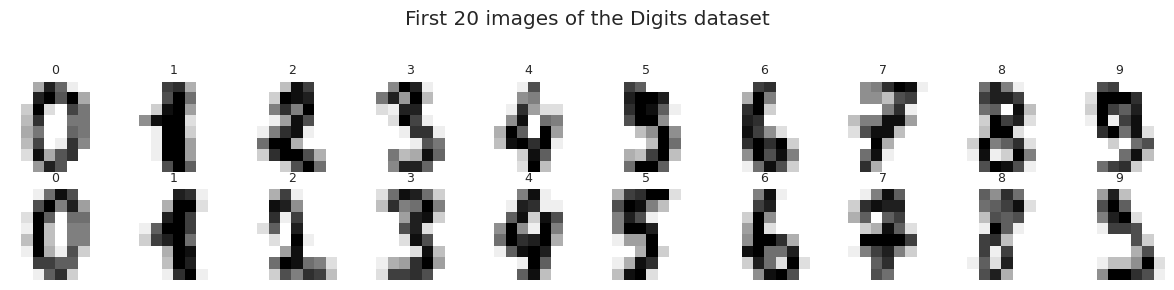

In [19]:
digits = load_digits()
print("Data shape:", digits.data.shape, "| classes:", np.unique(digits.target), "| images per class:", np.bincount(digits.target))

fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
for ax, img, lab in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab, fontsize=9); ax.axis("off")
plt.suptitle("First 20 images of the Digits dataset", y=1.03); plt.tight_layout(); plt.show()

### 4.3 t-SNE in a pipeline (the book's recipe)

As before, we scale first and then run t-SNE with `random_state=2024`. t-SNE has **no `transform()` method** (it only provides `fit_transform`), because the embedding is the result of an optimisation over exactly these points.

In [20]:
t0 = time.time()
tsne_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("tsne", TSNE(n_components=2, random_state=2024)),
])
X_tsne = tsne_pipeline.fit_transform(digits.data)
print(f"t-SNE finished in {time.time()-t0:.1f}s | output shape: {X_tsne.shape}")
print("Final KL divergence:", round(tsne_pipeline.named_steps["tsne"].kl_divergence_, 4))
print("Does TSNE have a transform() method for new data?", hasattr(TSNE(), "transform"))

t-SNE finished in 7.6s | output shape: (1797, 2)
Final KL divergence: 0.8369
Does TSNE have a transform() method for new data? False


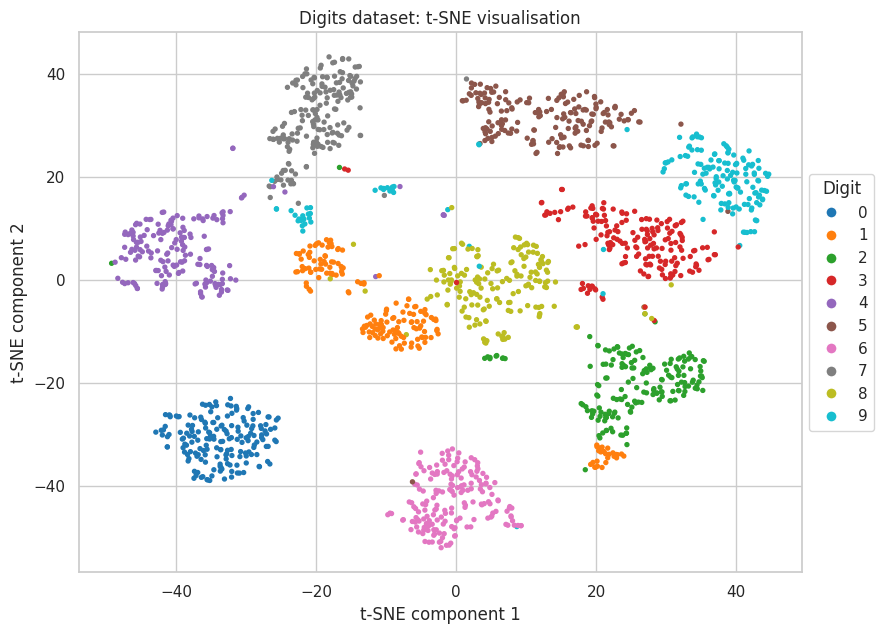

In [21]:
def plot_digits_embedding(Z, title, ax=None, legend=True):
    ax = ax or plt.gca()
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=digits.target, cmap="tab10", s=8)
    ax.set_title(title)
    if legend:
        handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=plt.cm.tab10(i / 9), markersize=8, label=str(i)) for i in range(10)]
        ax.legend(handles=handles, title="Digit", loc="center left", bbox_to_anchor=(1, 0.5))

fig, ax = plt.subplots(figsize=(9, 6.5))
plot_digits_embedding(X_tsne, "Digits dataset: t-SNE visualisation", ax)
ax.set_xlabel("t-SNE component 1"); ax.set_ylabel("t-SNE component 2")
plt.tight_layout(); plt.show()

In 64 dimensions, t-SNE reveals ten compact clusters that correspond to the ten digits. Look at which clusters sit next to each other: digits with similar shapes tend to be neighbours, while a distinctive digit such as 0 forms an isolated group. This is exactly the kind of insight t-SNE is good for.

### 4.4 The perplexity hyperparameter

**Perplexity** is roughly "the number of neighbours each point considers". Small values emphasise very local structure (and can produce many tiny fragments); large values emphasise global structure. Typical values are 5-50. The shape of the picture can change a lot, so it is good practice to try several.

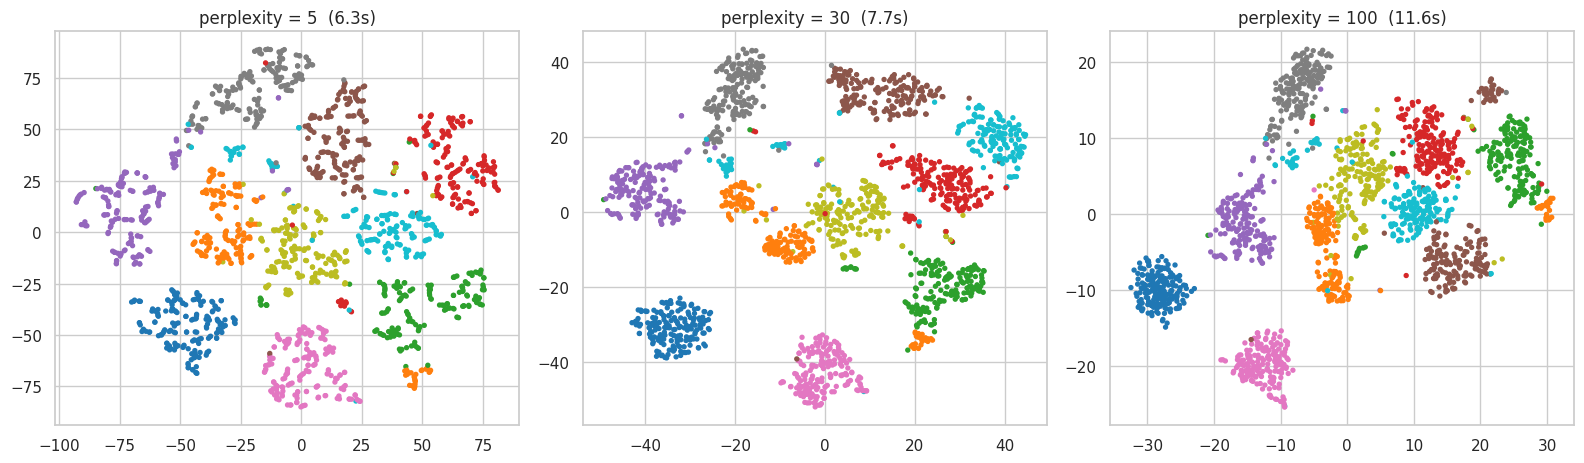

In [22]:
Xs_dig = StandardScaler().fit_transform(digits.data)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, perp in zip(axes, [5, 30, 100]):
    t0 = time.time()
    emb = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto", random_state=2024).fit_transform(Xs_dig)
    plot_digits_embedding(emb, f"perplexity = {perp}  ({time.time()-t0:.1f}s)", ax, legend=False)
plt.tight_layout(); plt.show()

With perplexity 5 the clusters are fragmented into many small pieces; at 30 the ten digits are mostly well separated (a few digits are still split into two sub-groups); at 100 the clusters are larger and compact but several of them touch. None is "the correct" picture, which is why t-SNE should be interpreted with care.

### 4.5 Caveats: what you can and cannot read from a t-SNE plot

| Can trust | Cannot trust |
|:----------|:-------------|
| Points that are close together are probably similar | The **distance between clusters** or the relative position of clusters |
| Clusters that appear are often real structure | The **size** or density of clusters |
| It helps to form hypotheses | Axis values (they have no meaning) |

Results also depend on the random initialisation. Two different seeds give two different, equally valid layouts:

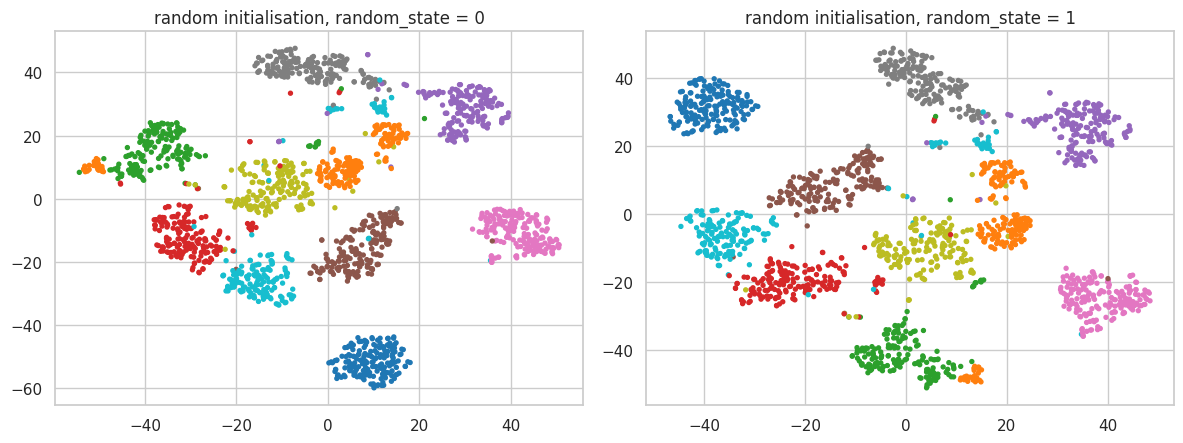

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, seed in zip(axes, [0, 1]):
    emb = TSNE(n_components=2, perplexity=30, init="random", learning_rate="auto", random_state=seed).fit_transform(Xs_dig)
    plot_digits_embedding(emb, f"random initialisation, random_state = {seed}", ax, legend=False)
plt.tight_layout(); plt.show()

The clusters themselves (digit groups) remain, but their **positions and orientation differ completely** between seeds. This is why we never interpret the absolute positions in a t-SNE map.

### 4.6 Speed-up: PCA before t-SNE

t-SNE is computationally intensive (it works with all pairwise similarities). A standard practice for high-dimensional data is to first reduce to about 30-50 dimensions with PCA (removing noise and cost), then run t-SNE. The effect is large for hundreds or thousands of input features; digits have only 64, so we should not expect (or see) a speed-up here, and the timing below simply shows that the extra PCA step costs little.

In [24]:
t0 = time.time(); TSNE(n_components=2, random_state=2024, init="pca", learning_rate="auto").fit(Xs_dig); t_direct = time.time() - t0
t0 = time.time()
Xp = PCA(n_components=30, random_state=0).fit_transform(Xs_dig)
emb_p = TSNE(n_components=2, random_state=2024, init="pca", learning_rate="auto").fit_transform(Xp)
t_pca = time.time() - t0
print(f"t-SNE on 64 features         : {t_direct:.1f}s")
print(f"PCA(30) + t-SNE on 30 features: {t_pca:.1f}s")
print(f"Variance kept by the 30 components: {PCA(n_components=30).fit(Xs_dig).explained_variance_ratio_.sum():.1%}")

t-SNE on 64 features         : 7.6s
PCA(30) + t-SNE on 30 features: 7.6s
Variance kept by the 30 components: 89.3%


### 4.7 Hands-on checklist for t-SNE
1. Understand the dataset and which features are relevant for the visualisation.
2. Scale the features.
3. Use `TSNE` to embed in 2-D (try several perplexities; set `random_state`).
4. Draw scatter plots coloured by labels or other attributes.
5. Analyse the clusters, but never over-interpret distances between them.

### 4.8 The three methods on the same data

For a final comparison, we project the Digits dataset to 2-D with PCA, LDA and t-SNE. LDA is applied on the standardised data with labels (10 classes allow up to 9 discriminants; we plot the first two).

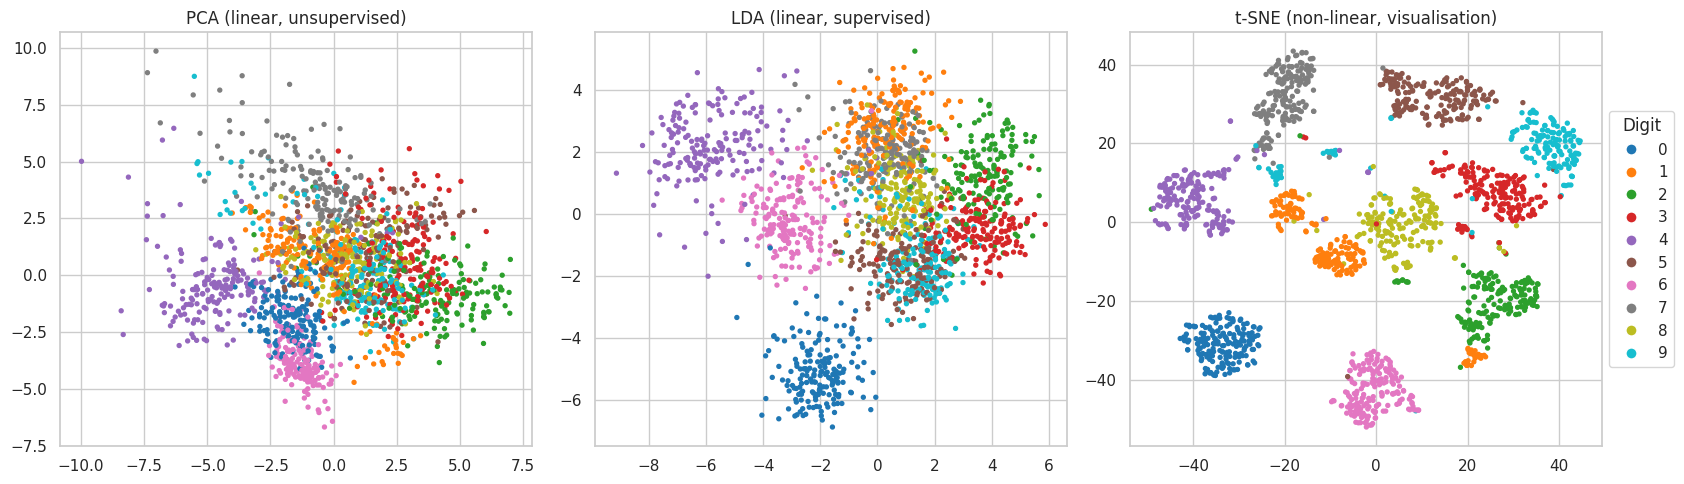

In [25]:
pca_dig = make_pipeline(StandardScaler(), PCA(n_components=2)).fit_transform(digits.data)
lda_dig = make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(n_components=2)).fit_transform(digits.data, digits.target)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (title, Z) in zip(axes, [("PCA (linear, unsupervised)", pca_dig), ("LDA (linear, supervised)", lda_dig), ("t-SNE (non-linear, visualisation)", X_tsne)]):
    plot_digits_embedding(Z, title, ax, legend=False)
handles = [plt.Line2D([0], [0], marker="o", color="w", markerfacecolor=plt.cm.tab10(i / 9), markersize=8, label=str(i)) for i in range(10)]
axes[-1].legend(handles=handles, title="Digit", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()

With ten classes, 2 linear dimensions are simply not enough: PCA and LDA show heavily overlapping classes, whereas the non-linear t-SNE map shows ten distinct clusters. This explains why t-SNE (and its modern relative UMAP) are the standard tools for *visualising* complex high-dimensional data, while PCA and LDA remain the tools for *feature extraction* in models.

## 5. Selecting the Right Technique

### 5.1 Comparison table

| Technique | Type | Purpose | Key features | Best use cases |
|:----------|:-----|:--------|:-------------|:---------------|
| **PCA** | Unsupervised, linear | Dimensionality reduction | Maximises variance; orthogonal linear combinations | Exploratory analysis, noise reduction, feature extraction, speeding up models |
| **LDA** | Supervised, linear | Dimensionality reduction | Maximises class separability; at most $C-1$ components | Classification tasks where class separation matters |
| **t-SNE** | Unsupervised, non-linear | Visualisation | Preserves local structure; reveals clusters | Visualising high-dimensional data; exploratory analysis |

### 5.2 Guidelines

| Question | If yes... |
|:---------|:----------|
| Do I have **labels** and care about classification? | LDA (or supervised feature selection) |
| No labels, want to retain **variance** / compress? | PCA |
| Just want to **look at** the structure in 2-3 D? | t-SNE (optionally after PCA) |
| Is the structure **non-linear**? | Kernel PCA, t-SNE (or UMAP) |
| Is the dataset **large**? | PCA (fast, scalable); t-SNE becomes expensive |
| Do I need **interpretability**? | Feature selection; LDA/PCA loadings help partially; t-SNE gives none |
| Do I need to transform **new data**? | PCA/LDA yes; t-SNE no (no `transform`) |

### 5.3 Practical steps
1. State the goal: better model performance, or visualisation?
2. Understand the data: labelled or not, how many dimensions?
3. Consider dataset size and computational resources.
4. If unsure, try several techniques (for example PCA followed by t-SNE) and compare.
5. Evaluate effectiveness through **model metrics** or the **clarity of the visualisation**.

## 6. Impact on Model Performance

Dimensionality reduction can simplify models and speed up training, but it is **not free**. The trade-offs:

| Trade-off | Benefit | Cost |
|:----------|:--------|:-----|
| **Complexity vs interpretability** | Fewer features, simpler model | PCs/discriminants are abstract; information may be lost |
| **Training time vs accuracy** | Faster training on fewer dimensions | Accuracy can drop if informative directions are discarded |
| **Overfitting vs generalisation** | Removing noise reduces overfitting | Removing too much causes *underfitting* |

### 6.1 Example 1 (book): PCA with logistic regression on Iris

We analyse how PCA before logistic regression affects performance on Iris. Logistic regression is the topic of Chapter 6, so treat it for now as "a standard classifier". Steps: load data → split → pipeline without PCA → pipeline with PCA → fit and evaluate → compare.

In [26]:
iris = load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.2, random_state=2024, stratify=yi)

pipe_no_pca = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(max_iter=1000))])
pipe_pca = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=2)), ("clf", LogisticRegression(max_iter=1000))])

for name, pipe in [("Without PCA (4 features)", pipe_no_pca), ("With PCA (2 components)", pipe_pca)]:
    pipe.fit(Xi_tr, yi_tr)
    print(f"{name:26s} train accuracy = {pipe.score(Xi_tr, yi_tr):.4f} | test accuracy = {pipe.score(Xi_te, yi_te):.4f}")

print("\nVariance retained by the 2 PCs:", round(pipe_pca.named_steps['pca'].explained_variance_ratio_.sum(), 4))

Without PCA (4 features)   train accuracy = 0.9667 | test accuracy = 0.9667
With PCA (2 components)    train accuracy = 0.9167 | test accuracy = 0.9333

Variance retained by the 2 PCs: 0.9573


On Iris, two components retain about 96% of the variance (the four measurements are strongly correlated), and the test accuracy drops slightly (one more misclassified sample out of 30). A single split on 30 test samples is a very noisy estimate, though, so we scan the number of components with cross-validation.

In [27]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=0)
rows = []
for k in [1, 2, 3, 4]:
    pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", LogisticRegression(max_iter=1000))])
    s = cross_val_score(pipe, Xi, yi, cv=cv10)
    var = PCA(n_components=k).fit(StandardScaler().fit_transform(Xi)).explained_variance_ratio_.sum()
    rows.append({"PCA components": k, "variance kept": var, "CV accuracy": s.mean(), "std": s.std()})
pd.DataFrame(rows).set_index("PCA components")

,variance kept,CV accuracy,std
PCA components,,,
1,0.7296,0.9200,0.0581
2,0.9581,0.9133,0.0600
3,0.9948,0.9533,0.0427
4,1.0000,0.9533,0.0427


The table shows the trade-off clearly. With **3 components** (99.5% of the variance) the accuracy equals that of the full 4-feature model, so we compress the data by 25% at no cost. With only 1-2 components the accuracy is a few points lower **even though 2 components keep about 96% of the variance**. This is an important lesson: PCA keeps the directions of largest *variance*, not necessarily the directions that best *discriminate the classes*; here some class-separating information lives in a low-variance direction that PCA discards. (This is exactly the situation in which a supervised method such as LDA can be better.)

### 6.2 Accuracy and training time versus the number of components (Digits)

For a bigger dataset the speed-accuracy trade-off is more informative. On the Digits data (64 pixel features) we vary the number of PCA components before a logistic-regression classifier.

            variance kept  CV accuracy  CV time (s)
components                                         
2                  0.2159       0.5404       0.1200
5                  0.4140       0.8114       0.1285
10                 0.5887       0.8843       0.1321
20                 0.7931       0.9421       0.1083
30                 0.8932       0.9538       0.1026
40                 0.9508       0.9633       0.0995
64                 1.0000       0.9694       0.1062


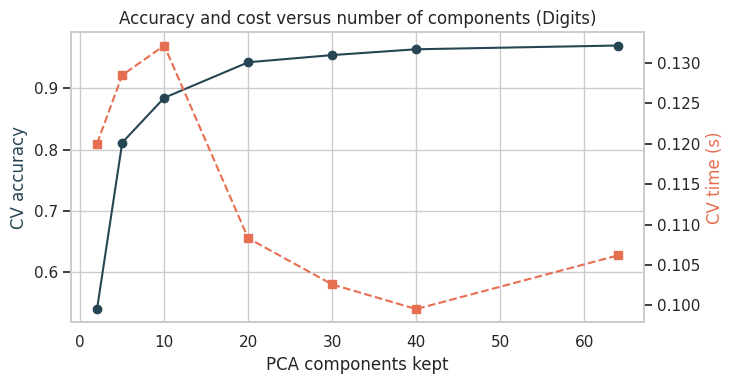

In [28]:
Xdg, ydg = digits.data, digits.target
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
rows = []
for k in [2, 5, 10, 20, 30, 40, 64]:
    pipe = Pipeline([("scaler", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", LogisticRegression(max_iter=3000))])
    t0 = time.time()
    s = cross_val_score(pipe, Xdg, ydg, cv=cv5)
    elapsed = time.time() - t0
    var = PCA(n_components=k).fit(StandardScaler().fit_transform(Xdg)).explained_variance_ratio_.sum()
    rows.append({"components": k, "variance kept": var, "CV accuracy": s.mean(), "CV time (s)": elapsed})
perf = pd.DataFrame(rows).set_index("components")
print(perf)

fig, ax1 = plt.subplots(figsize=(7.5, 4))
ax1.plot(perf.index, perf["CV accuracy"], "o-", color="#264653"); ax1.set_xlabel("PCA components kept"); ax1.set_ylabel("CV accuracy", color="#264653")
ax2 = ax1.twinx(); ax2.plot(perf.index, perf["CV time (s)"], "s--", color="#e76f51"); ax2.set_ylabel("CV time (s)", color="#e76f51"); ax2.grid(False)
plt.title("Accuracy and cost versus number of components (Digits)"); plt.tight_layout(); plt.show()

The accuracy curve rises steeply and then flattens with **diminishing returns**: 20 components already give about 94%, 30 give about 95%, 40 about 96%, versus about 97% for all 64 features. Using too few components (2-5) causes **underfitting**: the model lacks the information it needs. Notice also that the cross-validation time barely changes: logistic regression on 1797 samples is already so fast that reducing the dimensions saves almost nothing. The computational benefit of dimensionality reduction appears with large datasets and expensive models, which is the reason to always measure both accuracy *and* cost before deciding how many components to keep.

### 6.3 Example 2 (book): t-SNE for visualising clusters

The second book example uses t-SNE to *visualise* high-dimensional data and to check the structure that a clustering algorithm finds. We run **K-means** with 10 clusters on the original standardised 64-D data, then colour the t-SNE map by (a) the true digit labels and (b) the K-means labels. We quantify the agreement with the **Adjusted Rand Index** (ARI: 1 = perfect agreement, 0 = random labelling) and **Normalised Mutual Information** (NMI).

K-means (k=10) vs true digits: ARI = 0.460 | NMI = 0.621


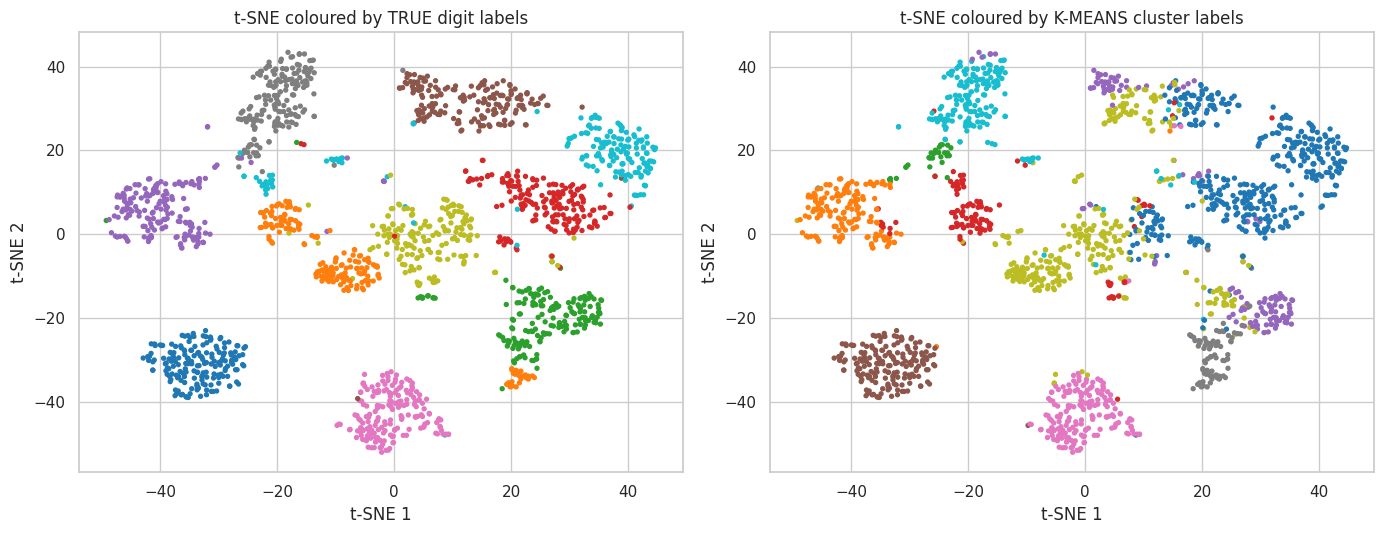

In [29]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

kmeans = KMeans(n_clusters=10, n_init=10, random_state=2024)
cluster_labels = kmeans.fit_predict(Xs_dig)

ari = adjusted_rand_score(digits.target, cluster_labels)
nmi = normalized_mutual_info_score(digits.target, cluster_labels)
print(f"K-means (k=10) vs true digits: ARI = {ari:.3f} | NMI = {nmi:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=digits.target, cmap="tab10", s=8); axes[0].set_title("t-SNE coloured by TRUE digit labels")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=cluster_labels, cmap="tab10", s=8); axes[1].set_title("t-SNE coloured by K-MEANS cluster labels")
for ax in axes:
    ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.show()

The same t-SNE map is coloured two ways. Where the colours of the two panels correspond (clean, compact clusters), K-means recovered the real classes; where one true digit is split between several K-means colours, or two digits share one colour, the algorithm confused them. The ARI/NMI values summarise this: K-means with no labels at all recovers a substantial part of the digit structure, but not perfectly, because pixel-space Euclidean distance is not a perfect similarity measure for handwriting. (Note that t-SNE was used only to *draw* the picture; the clustering was done in the original 64-D space.)

## Summary

- **Dimensionality reduction** simplifies data, lowers cost, can reduce overfitting and enables visualisation. High dimensions cause the *curse of dimensionality* (distance concentration and degraded KNN accuracy, both demonstrated).
- **PCA** (unsupervised, linear) finds orthogonal directions of maximum variance via the eigen-decomposition of the covariance matrix. We reproduced it from scratch, used the scree plot to choose components, interpreted loadings, saw reconstruction error, and showed why **scaling is mandatory**.
- **LDA** (supervised, linear) maximises class separability (Fisher's criterion) with at most $C-1$ components. It separates classes better than PCA but needs labels and must be fitted inside a pipeline to avoid leakage.
- **t-SNE** (unsupervised, non-linear) is a visualisation tool preserving local neighbourhoods. Perplexity matters, there is no `transform()` for new data, and distances between clusters must not be over-interpreted.
- **Choosing** depends on the goal (model vs visualisation), the availability of labels, linearity, dataset size, and interpretability needs.
- **Performance trade-offs:** accuracy plateaus after a moderate number of components, so we can often drop a good fraction of the dimensions at a small cost in accuracy, but too few components cause underfitting, and PCA's variance criterion is not guaranteed to preserve the class-relevant information.

In **Chapter 4** we move on to the core task of model building with models based on **distance metrics**, starting with k-nearest neighbours.